In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('mobile_phone_prices_bdt_sample.csv')

df.head(5)

,Brand,Model,RAM_GB,Storage_GB,Battery_mAh,Camera_MP,Price_BDT,Rating
0,Samsung,Galaxy A05,4,64,5000,50,12999,4.1
1,Samsung,Galaxy A15,6,128,5000,50,18999,4.3
2,Samsung,Galaxy A25,8,256,5000,50,32999,4.4
3,Samsung,Galaxy A35,8,128,5000,50,39999,4.5
4,Samsung,Galaxy A55,8,256,5000,50,54999,4.6


In [3]:
df.tail()

,Brand,Model,RAM_GB,Storage_GB,Battery_mAh,Camera_MP,Price_BDT,Rating
45,OnePlus,Nord 3,16,256,5000,50,49999,4.6
46,OnePlus,12R,16,256,5500,50,69999,4.7
47,Google,Pixel 7a,8,128,4385,64,44999,4.5
48,Google,Pixel 8,8,128,4575,50,69999,4.7
49,Google,Pixel 8 Pro,12,256,5050,50,109999,4.8


In [13]:
df.shape

(50, 8)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Brand        50 non-null     str    
 1   Model        50 non-null     str    
 2   RAM_GB       50 non-null     int64  
 3   Storage_GB   50 non-null     int64  
 4   Battery_mAh  50 non-null     int64  
 5   Camera_MP    50 non-null     int64  
 6   Price_BDT    50 non-null     int64  
 7   Rating       50 non-null     float64
dtypes: float64(1), int64(5), str(2)
memory usage: 3.3 KB


In [8]:
df.sample()

,Brand,Model,RAM_GB,Storage_GB,Battery_mAh,Camera_MP,Price_BDT,Rating
25,OPPO,Reno 11F,8,256,5000,64,34999,4.5


In [7]:
df.describe()

,RAM_GB,Storage_GB,Battery_mAh,Camera_MP,Price_BDT,Rating
count,50.000000,50.000000,50.000000,50.00000,50.000000,50.000000
mean,7.960000,198.400000,4773.540000,53.04000,38899.000000,4.382000
std,3.063678,94.353223,636.120038,31.53227,30400.892844,0.252085
min,4.000000,64.000000,2815.000000,8.00000,8999.000000,3.900000
25%,6.000000,128.000000,5000.000000,50.00000,17999.000000,4.200000
50%,8.000000,192.000000,5000.000000,50.00000,31499.000000,4.400000
75%,8.000000,256.000000,5000.000000,50.00000,49999.000000,4.600000
max,16.000000,512.000000,6000.000000,200.00000,159999.000000,4.900000


In [10]:
df.isnull().sum()

Brand          0
Model          0
RAM_GB         0
Storage_GB     0
Battery_mAh    0
Camera_MP      0
Price_BDT      0
Rating         0
dtype: int64

In [9]:
df.duplicated().sum()


np.int64(0)

In [11]:
df= df.fillna(df.median(numeric_only=True))

Statistical Analysis

In [47]:

print("Statistical Summary")
print(df.describe())

print("Average Price:", round(df['Price_BDT'].mean(), 2))

print("Highest Price:", df['Price_BDT'].max())

print("Lowest Price:", df['Price_BDT'].min())

print("Average RAM:", round(df['RAM_GB'].mean(), 2))

Statistical Summary
          RAM_GB  Storage_GB  Battery_mAh  Camera_MP      Price_BDT     Rating
count  50.000000   50.000000    50.000000   50.00000      50.000000  50.000000
mean    7.960000  198.400000  4773.540000   53.04000   38899.000000   4.382000
std     3.063678   94.353223   636.120038   31.53227   30400.892844   0.252085
min     4.000000   64.000000  2815.000000    8.00000    8999.000000   3.900000
25%     6.000000  128.000000  5000.000000   50.00000   17999.000000   4.200000
50%     8.000000  192.000000  5000.000000   50.00000   31499.000000   4.400000
75%     8.000000  256.000000  5000.000000   50.00000   49999.000000   4.600000
max    16.000000  512.000000  6000.000000  200.00000  159999.000000   4.900000
Average Price: 38899.0
Highest Price: 159999
Lowest Price: 8999
Average RAM: 7.96


Brand-wise Price Analysis

In [28]:
brand_analysis = df.groupby('Brand')['Price_BDT'].agg(
    Average_Price='mean',
    Minimum_Price='min',
    Maximum_Price='max'
)

brand_analysis = brand_analysis.round(2)

print("Brand-wise Mobile Phone Price Analysis:")
display(brand_analysis)

Brand-wise Mobile Phone Price Analysis:


,Average_Price,Minimum_Price,Maximum_Price
Brand,,,
Apple,90832.33,49999,159999
Google,74999.00,44999,109999
Infinix,16999.00,8999,27999
Motorola,26332.33,15999,39999
OPPO,29399.00,13999,59999
OnePlus,49999.00,29999,69999
Realme,23799.00,11999,44999
Samsung,38332.33,12999,69999
Tecno,19749.00,8999,34999


Visualizing Average Price by Brand

Text(0, 0.5, 'Average Price (BDT)')

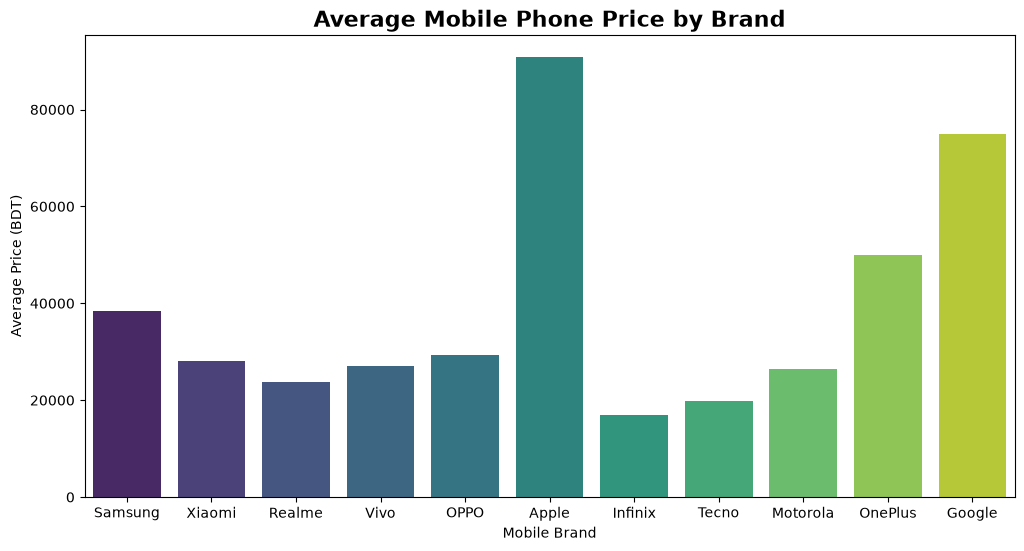

In [30]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x='Brand',
    y='Price_BDT',
    estimator='mean',
    errorbar=None,
    palette='viridis',
    hue='Brand'
)

plt.title('Average Mobile Phone Price by Brand',
          fontsize=16, fontweight='bold')

plt.xlabel('Mobile Brand')
plt.ylabel('Average Price (BDT)')


 RAM vs Mobile Phone Price Analysis(scatterplot)

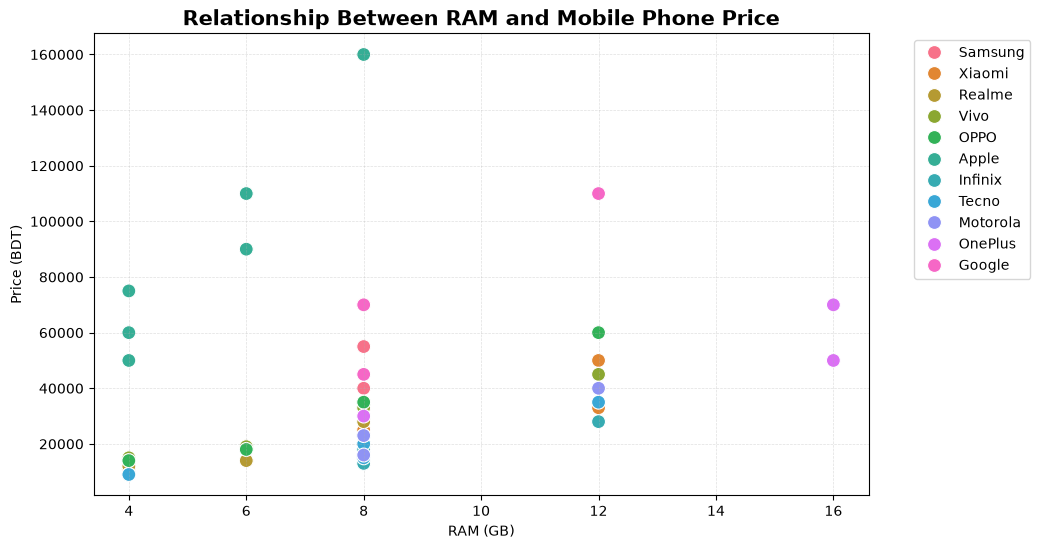

In [31]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='RAM_GB',
    y='Price_BDT',
    hue='Brand',
    palette='husl',
    s=100
)

plt.title('Relationship Between RAM and Mobile Phone Price',
          fontsize=15, fontweight='bold')

plt.xlabel('RAM (GB)')
plt.ylabel('Price (BDT)')

plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

Storage vs Price Analysis

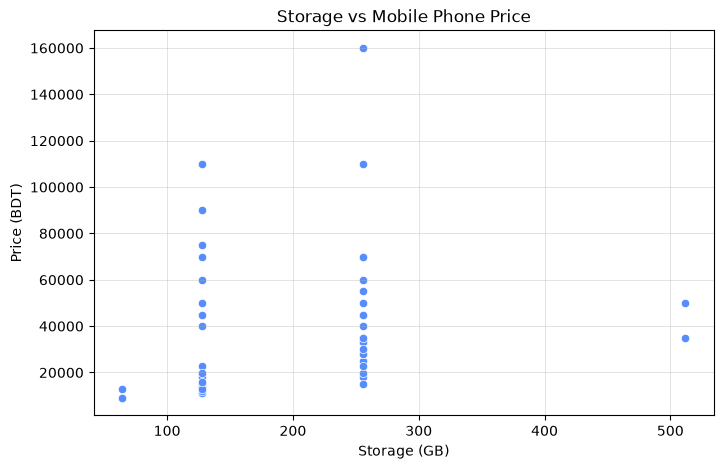

In [34]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='Storage_GB', y='Price_BDT')

plt.title('Storage vs Mobile Phone Price')
plt.xlabel('Storage (GB)')
plt.ylabel('Price (BDT)')
plt.grid()


Battery vs Price Analysis

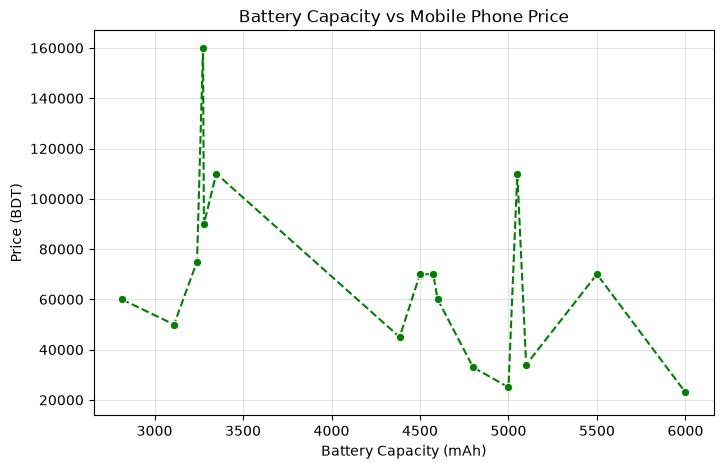

In [14]:
plt.figure(figsize=(8, 5))

sns.lineplot(data=df, x='Battery_mAh', y='Price_BDT',color='green',linestyle='dashed',marker='o')

plt.title('Battery Capacity vs Mobile Phone Price')
plt.xlabel('Battery Capacity (mAh)')
plt.ylabel('Price (BDT)')

plt.grid()
plt.show()

 Correlation Analysis

In [15]:
correlation = df.corr(numeric_only=True)

display(correlation)

,RAM_GB,Storage_GB,Battery_mAh,Camera_MP,Price_BDT,Rating
RAM_GB,1.000000,0.678663,0.341706,0.308871,0.258952,0.548687
Storage_GB,0.678663,1.000000,0.224215,0.303266,0.210142,0.466216
Battery_mAh,0.341706,0.224215,1.000000,0.339107,-0.614737,-0.416039
Camera_MP,0.308871,0.303266,0.339107,1.000000,-0.102589,0.138991
Price_BDT,0.258952,0.210142,-0.614737,-0.102589,1.000000,0.857777
Rating,0.548687,0.466216,-0.416039,0.138991,0.857777,1.000000


Correlation Heatmap

Text(0.5, 1.0, 'Mobile Phone Correlation Heatmap')

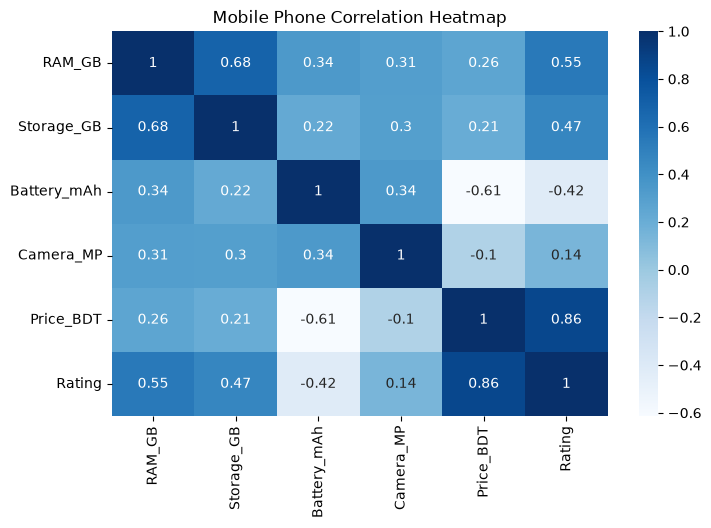

In [20]:
plt.figure(figsize=(8, 5))

sns.heatmap(correlation, annot=True, cmap='Blues')

plt.title('Mobile Phone Correlation Heatmap')

 Mobile Phone Price Distribution(histplot)

Text(0, 0.5, 'Frequency')

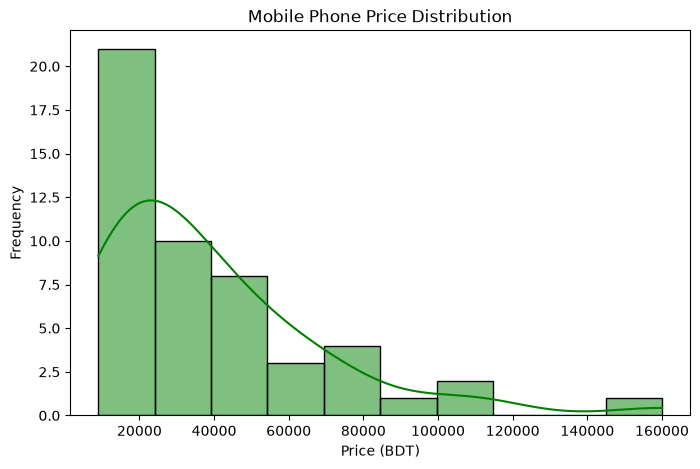

In [22]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Price_BDT', bins=10, kde=True, color='green')

plt.title('Mobile Phone Price Distribution')
plt.xlabel('Price (BDT)')
plt.ylabel('Frequency')


Histogram of RAM Distribution

Text(0, 0.5, 'Frequency')

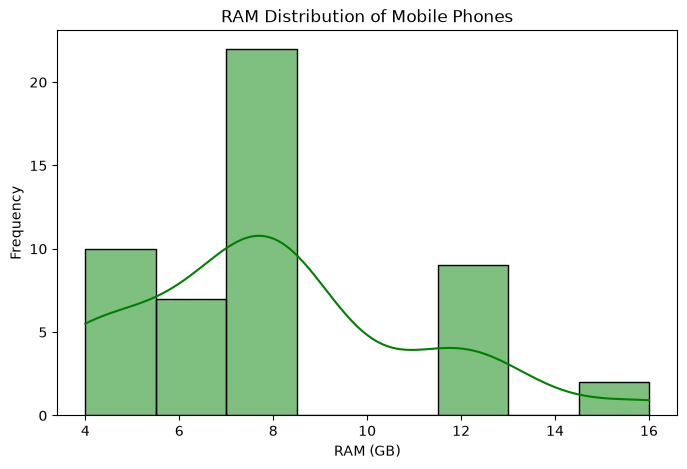

In [27]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='RAM_GB', bins=8, kde=True, color='green')

plt.title('RAM Distribution of Mobile Phones')
plt.xlabel('RAM (GB)')
plt.ylabel('Frequency')

 Brand Distribution

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
 [Text(0, 0, 'Samsung'),
  Text(1, 0, 'Xiaomi'),
  Text(2, 0, 'Realme'),
  Text(3, 0, 'Vivo'),
  Text(4, 0, 'OPPO'),
  Text(5, 0, 'Apple'),
  Text(6, 0, 'Infinix'),
  Text(7, 0, 'Tecno'),
  Text(8, 0, 'Motorola'),
  Text(9, 0, 'OnePlus'),
  Text(10, 0, 'Google')])

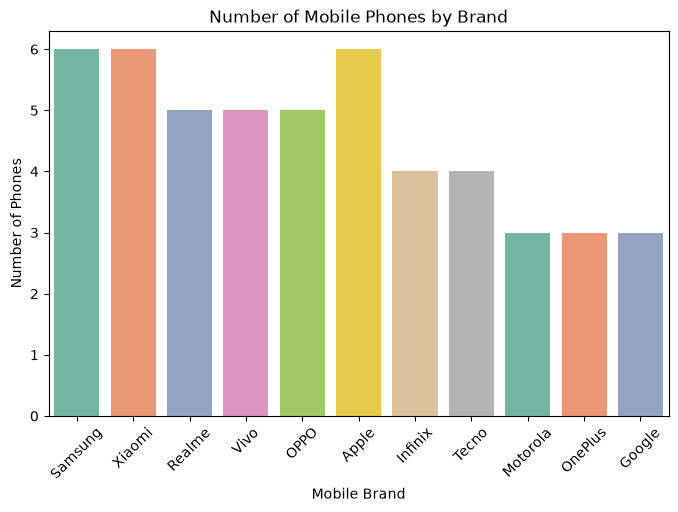

In [28]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Brand', hue='Brand', palette='Set2', legend=False)

plt.title('Number of Mobile Phones by Brand')
plt.xlabel('Mobile Brand')
plt.ylabel('Number of Phones')

plt.xticks(rotation=45)

Storage Distribution

Text(0, 0.5, 'Frequency')

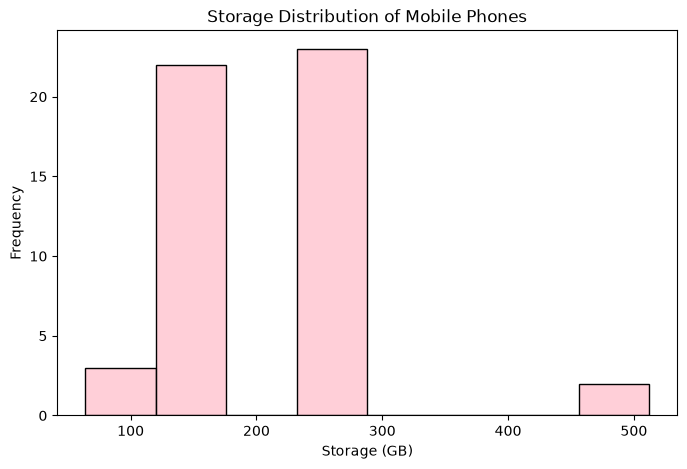

In [37]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Storage_GB', bins=8, color='pink')

plt.title('Storage Distribution of Mobile Phones')
plt.xlabel('Storage (GB)')
plt.ylabel('Frequency')

Battery Distribution Analysis

Text(0, 0.5, 'Frequency')

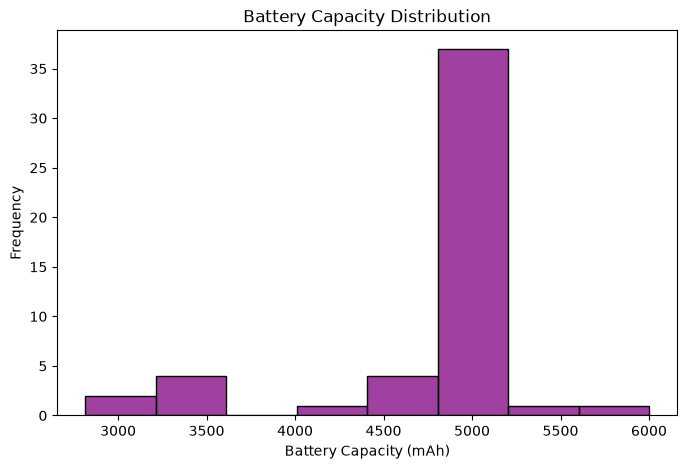

In [34]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Battery_mAh', bins=8, color='purple')

plt.title('Battery Capacity Distribution')
plt.xlabel('Battery Capacity (mAh)')
plt.ylabel('Frequency')

Project Summary

In [48]:
print("===== MOBILE PHONE ANALYSIS =====")

print("Total Phones:", len(df))
print("Total Brands:", df['Brand'].nunique())
print("Average Price:", round(df['Price_BDT'].mean(), 2))
print("Average RAM:", round(df['RAM_GB'].mean(), 2))
print("Average Battery:", round(df['Battery_mAh'].mean(), 2))

print("=================================")

===== MOBILE PHONE ANALYSIS =====
Total Phones: 50
Total Brands: 11
Average Price: 38899.0
Average RAM: 7.96
Average Battery: 4773.54


 Top 5 Most Expensive Mobile Phones

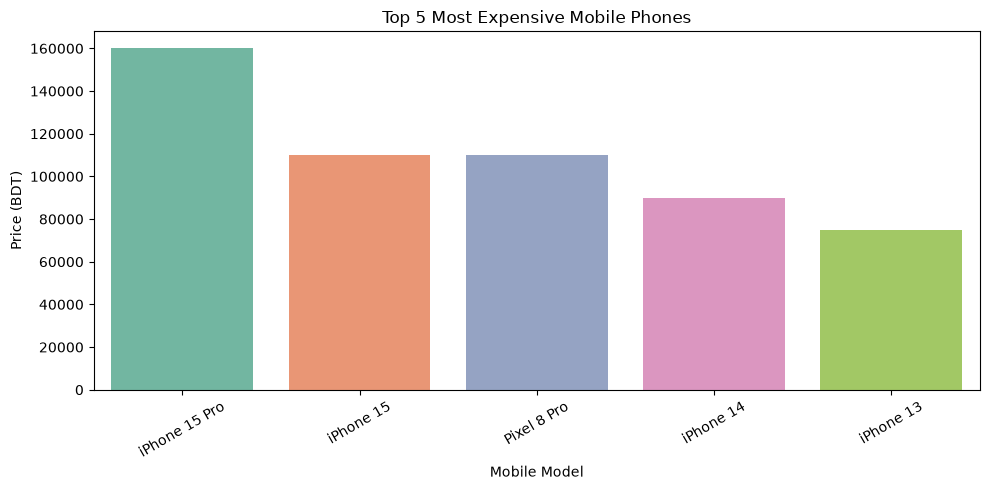

In [49]:
top_phones = df.nlargest(5, 'Price_BDT')

plt.figure(figsize=(10, 5))

sns.barplot(data=top_phones, x='Model', y='Price_BDT',
            hue='Model', palette='Set2', legend=False)

plt.title('Top 5 Most Expensive Mobile Phones')
plt.xlabel('Mobile Model')
plt.ylabel('Price (BDT)')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Top 5 Popular Brands

Text(0, 0.5, 'Number of Phones')

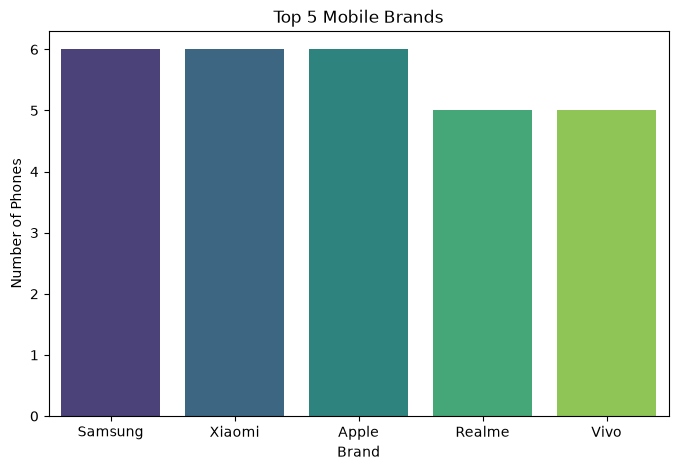

In [50]:
top_brands = df['Brand'].value_counts().head(5)

plt.figure(figsize=(8, 5))

sns.barplot(x=top_brands.index, y=top_brands.values,
            hue=top_brands.index, palette='viridis',
            legend=False)

plt.title('Top 5 Mobile Brands')
plt.xlabel('Brand')
plt.ylabel('Number of Phones')

RAM Comparison Chart

Text(0, 0.5, 'Average Price (BDT)')

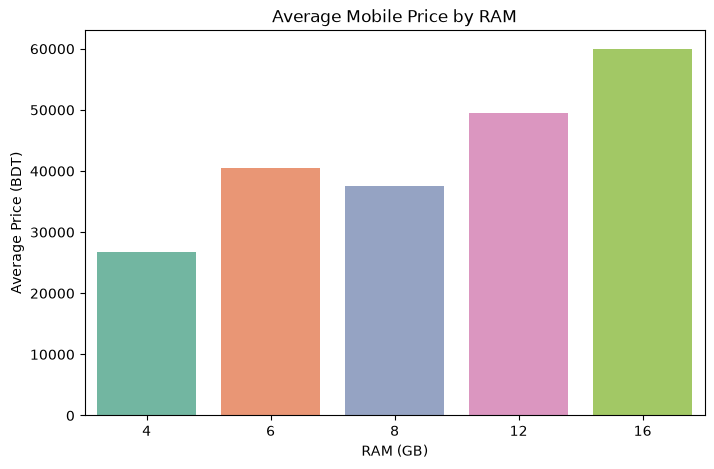

In [51]:
ram_price = df.groupby('RAM_GB')['Price_BDT'].mean()

plt.figure(figsize=(8, 5))

sns.barplot(x=ram_price.index, y=ram_price.values,
            hue=ram_price.index, palette='Set2',
            legend=False)

plt.title('Average Mobile Price by RAM')
plt.xlabel('RAM (GB)')
plt.ylabel('Average Price (BDT)')


Price Category Analysis

Text(0, 0.5, 'Number of Phones')

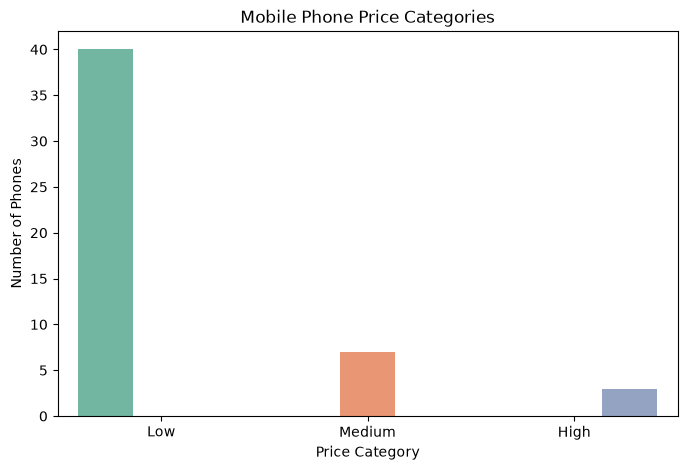

In [52]:
df['Price_Category'] = pd.cut(
    df['Price_BDT'],
    bins=3,
    labels=['Low', 'Medium', 'High']
)

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Price_Category',
              hue='Price_Category', palette='Set2',
              legend=False)

plt.title('Mobile Phone Price Categories')
plt.xlabel('Price Category')
plt.ylabel('Number of Phones')


Average Price by Brand

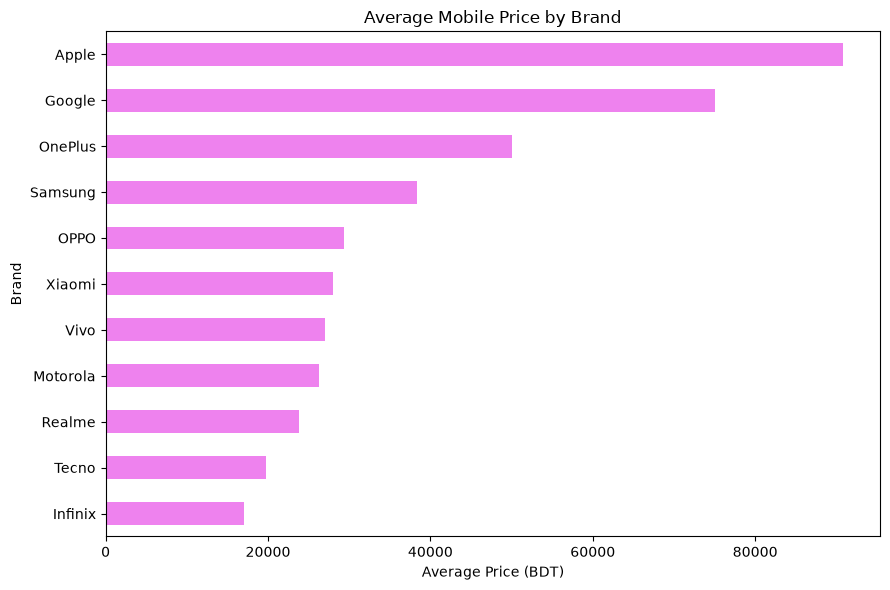

In [54]:
brand_price = df.groupby('Brand')['Price_BDT'].mean()

plt.figure(figsize=(9, 6))

brand_price.sort_values().plot(kind='barh', color='violet')

plt.title('Average Mobile Price by Brand')
plt.xlabel('Average Price (BDT)')
plt.ylabel('Brand')

plt.tight_layout()

Price Distribution by Brand

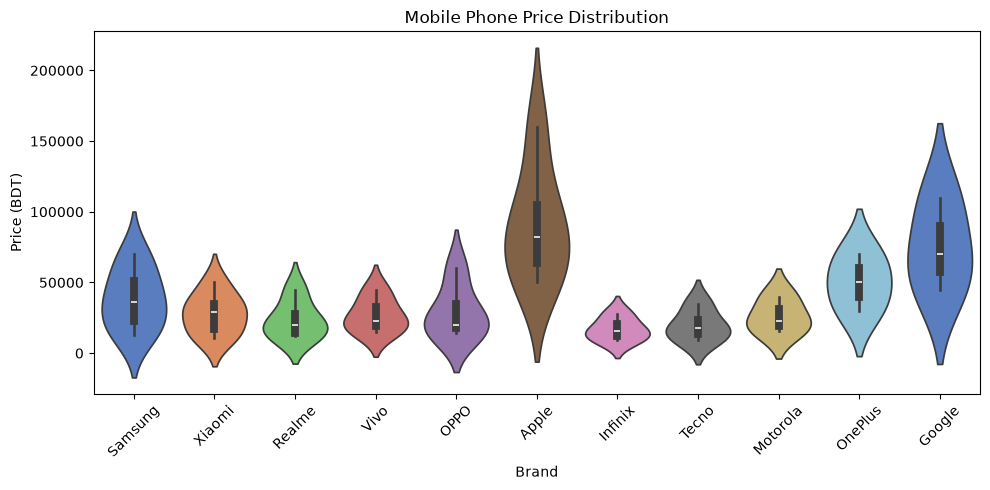

In [55]:
plt.figure(figsize=(10, 5))

sns.violinplot(data=df, x='Brand', y='Price_BDT',
               hue='Brand', palette='muted',
               legend=False)

plt.title('Mobile Phone Price Distribution')
plt.xlabel('Brand')
plt.ylabel('Price (BDT)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Final Project Completion

In [57]:
print("====================================")
print(" MOBILE PHONE PRICE ANALYSIS")
print("====================================")
print("Data Analysis: Completed")
print("Data Visualization: Completed")
print("Statistical Analysis: Completed")
print("Project Status: Successfully Completed!")
print("Thank You!")
print("====================================")

 MOBILE PHONE PRICE ANALYSIS
Data Analysis: Completed
Data Visualization: Completed
Statistical Analysis: Completed
Project Status: Successfully Completed!
Thank You!
